# 01. Exploratory Data Analysis (EDA)
## Medical Appointment No-Show Prediction & Demand Forecasting

### Center of Specialization in Physical and Intellectual Rehabilitation (CER)
This notebook conducts a thorough exploratory data analysis on the medical appointment dataset comprising **109,593 records** across **26 columns** and **498 continuous calendar days** (2020-01-01 to 2021-05-12).

---
### Objectives:
1. Audit dataset dimensions, data types, missing values, and duplicate records.
2. Analyze overall attendance distribution and class imbalance (~31.8% no-show rate).
3. Investigate demographic patterns: age distribution, gender, disability types, and caregiver presence.
4. Explore rehabilitation specialties and attendance variations.
5. Examine environmental and weather effects (heat intensity, rain intensity, temperature).
6. Analyze temporal trends across continuous calendar days, days of the week, and monthly shifts.


In [1]:
from pathlib import Path
import sys
REPO_ROOT = Path.cwd()
if not (REPO_ROOT / 'src').exists():
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
%matplotlib inline

# Load raw dataset
df_raw = pd.read_csv('../data/raw.csv')
print(f"Dataset Shape: {df_raw.shape}")
print(f"Columns: {df_raw.columns.tolist()}")


Dataset Shape: (109593, 26)
Columns: ['specialty', 'appointment_time', 'gender', 'no_show', 'disability', 'place', 'appointment_shift', 'age', 'under_12_years_old', 'over_60_years_old', 'patient_needs_companion', 'average_temp_day', 'average_rain_day', 'max_temp_day', 'max_rain_day', 'rainy_day_before', 'storm_day_before', 'rain_intensity', 'heat_intensity', 'appointment_date_continuous', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'Scholarship', 'SMS_received']


### 1. Data Integrity and Missing Values Audit

In [3]:
# Check duplicate records
num_duplicates = df_raw.duplicated().sum()
print(f"Exact Duplicate Rows: {num_duplicates}")

# Missing values audit
null_summary = pd.DataFrame({
    'Missing Count': df_raw.isnull().sum(),
    'Missing Pct (%)': (df_raw.isnull().sum() / len(df_raw)) * 100
})
null_summary[null_summary['Missing Count'] > 0].sort_values('Missing Count', ascending=False)


Exact Duplicate Rows: 36


,Missing Count,Missing Pct (%)
age,22960,20.950243
specialty,20127,18.365224
disability,16601,15.147865
place,11539,10.528957
max_rain_day,2263,2.064913
average_rain_day,2245,2.048488
max_temp_day,2227,2.032064
average_temp_day,2211,2.017465


### 2. Target Variable Analysis: Attendance vs. No-Show
The positive class is `no_show == 'yes'` (patient missed the appointment), representing ~31.8% of records.

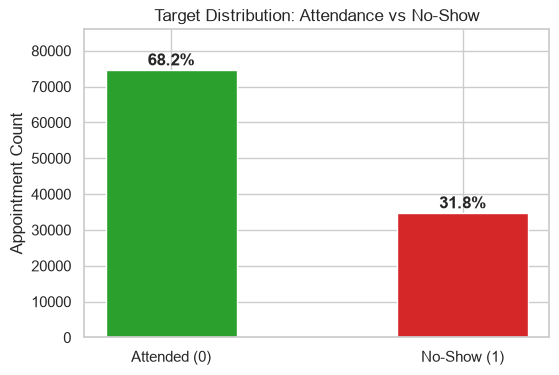

In [4]:
df_clean = df_raw.drop_duplicates().reset_index(drop=True)
df_clean['target'] = (df_clean['no_show'].str.lower().str.strip() == 'yes').astype(int)

counts = df_clean['target'].value_counts()
pcts = df_clean['target'].value_counts(normalize=True) * 100

plt.figure(figsize=(6, 4))
bars = plt.bar(['Attended (0)', 'No-Show (1)'], counts, color=['#2ca02c', '#d62728'], width=0.45)
for bar, pct in zip(bars, pcts):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1200, f"{pct:.1f}%", ha='center', fontweight='bold')
plt.title('Target Distribution: Attendance vs No-Show')
plt.ylabel('Appointment Count')
plt.ylim(0, max(counts) * 1.15)
plt.show()


### 3. Demographic Patterns: Age, Caregiver, and Disability

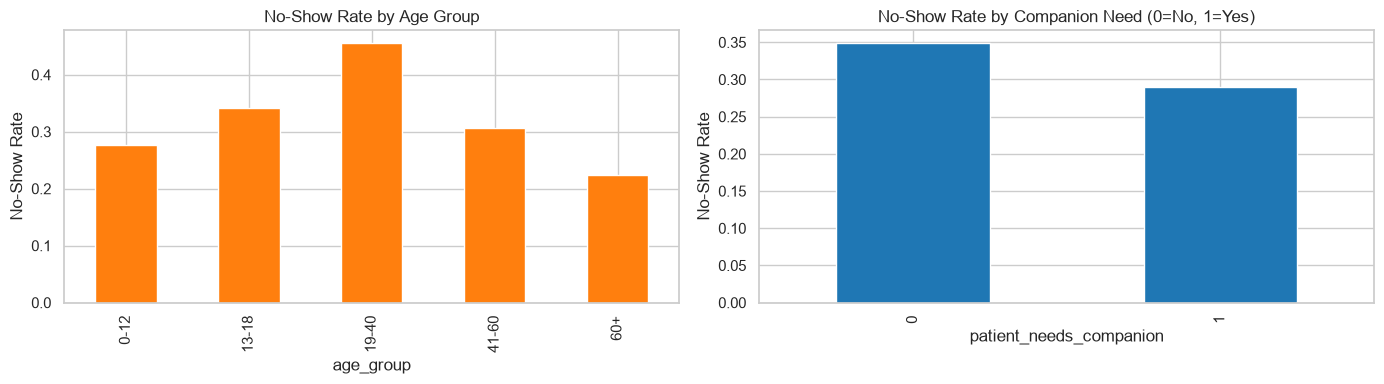

In [5]:
# Age analysis
df_clean['age_group'] = pd.cut(
    df_clean['age'].fillna(18),
    bins=[-1, 12, 18, 40, 60, 150],
    labels=['0-12', '13-18', '19-40', '41-60', '60+']
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df_clean.groupby('age_group')['target'].mean().plot(kind='bar', color='#ff7f0e', ax=axes[0])
axes[0].set_title('No-Show Rate by Age Group')
axes[0].set_ylabel('No-Show Rate')

df_clean.groupby('patient_needs_companion')['target'].mean().plot(kind='bar', color='#1f77b4', ax=axes[1])
axes[1].set_title('No-Show Rate by Companion Need (0=No, 1=Yes)')
axes[1].set_ylabel('No-Show Rate')
plt.tight_layout()
plt.show()


### 4. Specialty and Shift Attendance Analysis

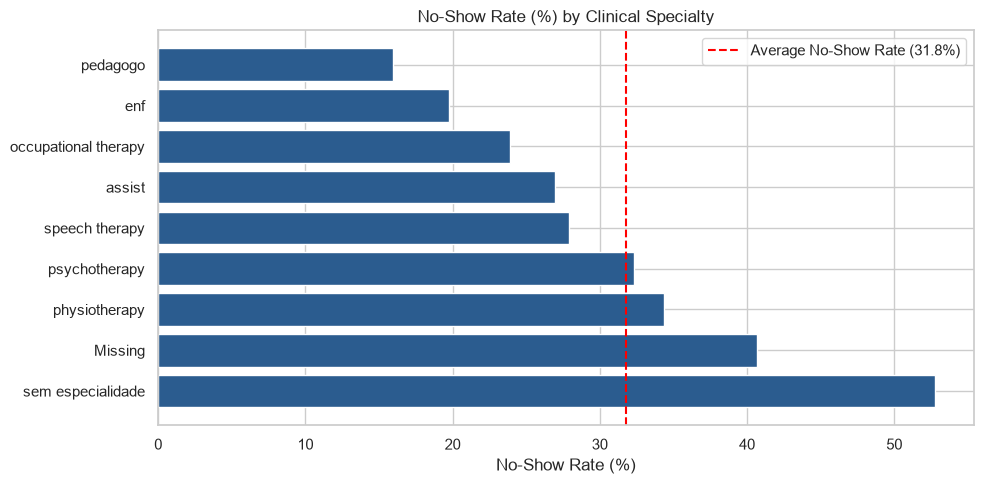

In [6]:
spec_rates = df_clean.groupby(df_clean['specialty'].fillna('Missing'))['target'].agg(['mean', 'count']).reset_index()
spec_rates = spec_rates.sort_values('mean', ascending=False)

plt.figure(figsize=(10, 5))
plt.barh(spec_rates['specialty'], spec_rates['mean'] * 100, color='#2b5c8f')
plt.axvline(31.8, color='red', linestyle='--', label='Average No-Show Rate (31.8%)')
plt.title('No-Show Rate (%) by Clinical Specialty')
plt.xlabel('No-Show Rate (%)')
plt.legend()
plt.tight_layout()
plt.show()


### 5. Environmental & Weather Factors
Exploring how extreme heat intensity and precipitation influence attendance.

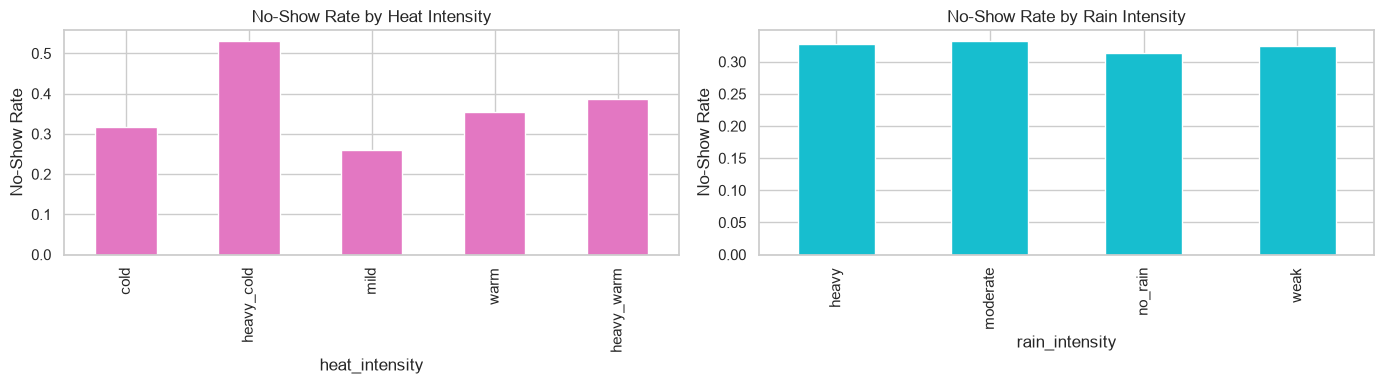

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
heat_order = ['cold', 'heavy_cold', 'mild', 'warm', 'heavy_warm']
df_clean.groupby('heat_intensity')['target'].mean().reindex(heat_order).plot(kind='bar', color='#e377c2', ax=axes[0])
axes[0].set_title('No-Show Rate by Heat Intensity')
axes[0].set_ylabel('No-Show Rate')

df_clean.groupby('rain_intensity')['target'].mean().plot(kind='bar', color='#17becf', ax=axes[1])
axes[1].set_title('No-Show Rate by Rain Intensity')
axes[1].set_ylabel('No-Show Rate')
plt.tight_layout()
plt.show()


### 6. Temporal Demand Overview Across the 498 Continuous Days

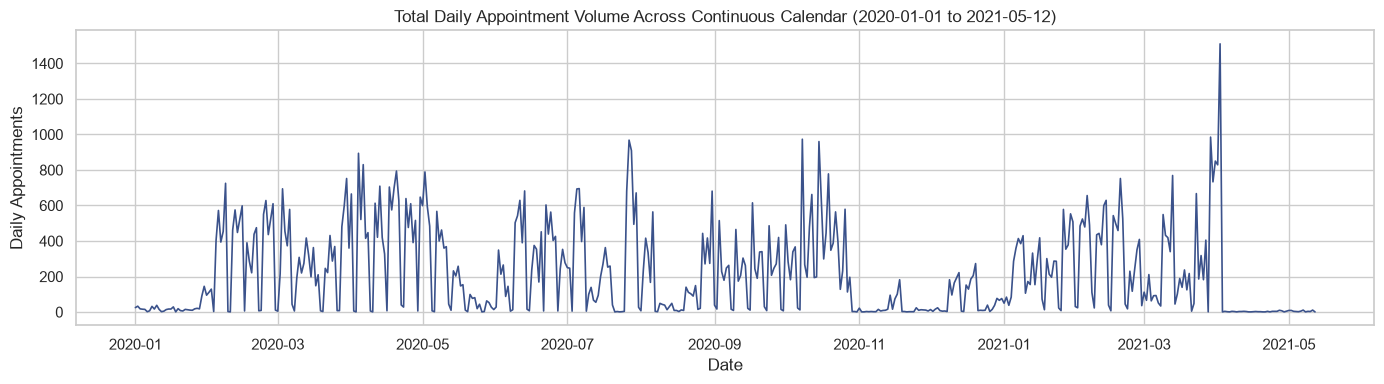

In [8]:
df_clean['date'] = pd.to_datetime(df_clean['appointment_date_continuous'])
daily = df_clean.groupby('date').size()

plt.figure(figsize=(14, 4))
plt.plot(daily.index, daily.values, color='#3b528b', lw=1.2)
plt.title('Total Daily Appointment Volume Across Continuous Calendar (2020-01-01 to 2021-05-12)')
plt.xlabel('Date')
plt.ylabel('Daily Appointments')
plt.tight_layout()
plt.show()


### Key Findings Summary:
1. **Target Class Imbalance**: ~31.8% positive no-shows vs 68.2% attended.
2. **Weather Sensitivity**: Severe cold increases no-show rate to **52.9%** (critical for rehabilitation patients with physical handicaps).
3. **Clinical Specialty**: Missing specialty entries or unassigned appointments reach **52.8%** no-show rate; pedagogy and nursing have high commitment (>80% attendance).
4. **Caregiver Inclusivity**: Companion-assisted patients have significantly lower no-show rates (29.0%) than unaccompanied individuals (34.8%).
5. **Continuous Calendar**: 498 continuous dates exhibit strong weekly seasonality (7-day cycles) and low Sunday operations.
